# Part 2 · Open Food Facts pretrained LayoutLMv3 BIO tagging

This notebook uses the manually downloaded `part2/weights/model.onnx` checkpoint when present, with ONNX Runtime CPU as the preferred backend. A local `model.safetensors` fallback is supported through Transformers. The model was fine-tuned by Open Food Facts; revision `4c28d479f332339ffc367d9aae66036a4583127c`, license `cc-by-nc-sa-4.0`. No model weights are downloaded.

Inference reuses the official `openfoodfacts/nutrient-detection-layout` test data: image + dataset-supplied OCR tokens + corresponding original 0–1000 bounding boxes. It does not train a model, modify annotations, or call a hosted API.

## BIO in one minute
BIO tags mark the beginning and continuation of a labeled token span. Example: `Fat → O`, `18 → B-FAT_100G`, `g → I-FAT_100G`. `B-` starts the annotated value span, `I-` continues it, and `O` means outside an annotated span. Nutrient names such as ‘Fat’ are generally `O`; labels describe nutrient value/unit spans and their basis class.

The inference uses adaptive overlapping OCR-word windows. Logits are projected back to the original words through fast-tokenizer `word_ids`; covered-token and gold-entity coverage are reported. Evaluation uses the untouched official test labels and a fixed seed. Small-subset results are exploratory, not the complete published test score. The model card's reported metrics are not copied as measured results.

In [1]:
from pathlib import Path
import sys
import importlib
import pandas as pd
import numpy as np
import random
from IPython.display import display
import torch
import transformers
from transformers import LayoutLMv3ForTokenClassification, LayoutLMv3Processor

ROOT = Path.cwd().resolve()
if ROOT.name == 'part2':
    ROOT = ROOT.parent
if not (ROOT / 'app.py').is_file() and (ROOT.parent / 'app.py').is_file():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
SRC = ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from part2.config import DatasetConfig
from part2.dataset import BIO_LABELS, HuggingFaceNutritionDataset
import part2.layoutlm_bio as layoutlm_bio
layoutlm_bio = importlib.reload(layoutlm_bio)
MODEL_ID = layoutlm_bio.MODEL_ID
MODEL_LICENSE = layoutlm_bio.MODEL_LICENSE
MODEL_REVISION = layoutlm_bio.MODEL_REVISION
MODEL_CACHE_DIR = layoutlm_bio.MODEL_CACHE_DIR
INFERENCE_CACHE_DIR = layoutlm_bio.INFERENCE_CACHE_DIR
resource_snapshot = layoutlm_bio.resource_snapshot
load_pretrained_model = layoutlm_bio.load_pretrained_model
predict_record = layoutlm_bio.predict_record
to_coarse_bio = layoutlm_bio.to_coarse_bio
rule_baseline_coarse_bio = layoutlm_bio.rule_baseline_coarse_bio
evaluate_sequences = layoutlm_bio.evaluate_sequences
draw_prediction_boxes = layoutlm_bio.draw_prediction_boxes
decode_bio_entities = layoutlm_bio.decode_bio_entities
analyze_bio_errors = layoutlm_bio.analyze_bio_errors

MODEL_DIR = ROOT / MODEL_CACHE_DIR
INFERENCE_DIR = ROOT / INFERENCE_CACHE_DIR
print({'model': MODEL_ID, 'revision': MODEL_REVISION, 'license': MODEL_LICENSE, 'device': 'cpu', 'torch': torch.__version__, 'transformers': transformers.__version__, 'cuda_available': torch.cuda.is_available(), 'processor_class': LayoutLMv3Processor.__name__, 'model_class': LayoutLMv3ForTokenClassification.__name__})

c:\Users\SaniaJawaid\Documents\projects\practice\study\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'model': 'openfoodfacts/nutrition-extractor', 'revision': '4c28d479f332339ffc367d9aae66036a4583127c', 'license': 'cc-by-nc-sa-4.0', 'device': 'cpu', 'torch': '2.14.1+cpu', 'transformers': '4.57.6', 'cuda_available': False, 'processor_class': 'LayoutLMv3Processor', 'model_class': 'LayoutLMv3ForTokenClassification'}


## 1. Check local files and resources before loading weights

The model checkpoint was manually placed at `part2/weights/model.onnx` (1,429,090,779 bytes; about 1.33 GiB). The adjacent ONNX config, processor, tokenizer, and exact 71-label map are checked locally. The code never fetches weights. ONNX CPU loading requires at least 2.5 GiB currently available physical RAM, leaving headroom beyond the checkpoint for session staging and activations; the safetensors fallback requires 6 GiB. If the gate fails, no model session or test image is loaded. Close memory-heavy programs and rerun the resource check.

In [2]:
resources = resource_snapshot(MODEL_DIR)
display(pd.Series(resources, name='resource check'))
print({'dataset_split': 'official test', 'first_request_images': 1, 'optional_max_images': 3, 'runtime': 'ONNX Runtime CPU preferred'})
print('No ONNX session is opened by this resource-check cell.')

available_ram_gb         3.78
free_disk_gb           270.93
weights_cached           True
onnx_weights_cached      True
safetensors_cached      False
checkpoint_size_gb       1.33
safe_to_load             True
safe_to_download         True
Name: resource check, dtype: object

{'dataset_split': 'official test', 'first_request_images': 1, 'optional_max_images': 3, 'runtime': 'ONNX Runtime CPU preferred'}
No ONNX session is opened by this resource-check cell.


### Local processor/tokenizer smoke test (no checkpoint load)

In [14]:
from PIL import Image

local_processor = LayoutLMv3Processor.from_pretrained(
    str(MODEL_DIR), apply_ocr=False, local_files_only=True,
)
smoke_encoding = local_processor(
    Image.new('RGB', (224, 224), 'white'),
    ['Fat', '18', 'g'],
    boxes=[[10, 10, 200, 80], [210, 10, 300, 80], [305, 10, 350, 80]],
    truncation=True,
    max_length=32,
    return_tensors='np',
)
smoke_word_ids = smoke_encoding.word_ids(batch_index=0)
print({
    'local_processor_loaded': True,
    'image_tensor_shape': smoke_encoding['pixel_values'].shape,
    'tokenizer_ids_shape': smoke_encoding['input_ids'].shape,
    'word_ids': smoke_word_ids,
    'model_weights_loaded': False,
})

{'local_processor_loaded': True, 'image_tensor_shape': (1, 3, 224, 224), 'tokenizer_ids_shape': (1, 5), 'word_ids': [None, 0, 1, 2, None], 'model_weights_loaded': False}


## 2. Run inference with the local ONNX checkpoint

The local `part2/weights/model.onnx` is preferred. The processor, tokenizer, and exact 71-label mapping are loaded from the small adjacent config files. The loader is local-only: it will not download model or tokenizer files. Inference uses ONNX Runtime's CPU provider with sequential execution and one intra-op thread.

The processor uses the model's saved LayoutLMv3 image settings (224×224, RGB normalization, OCR disabled) and passes the supplied OCR words and normalized bounding boxes. Word-level predictions are recovered from the fast tokenizer's `word_ids`, selecting the first subword's label for each original token, as required by the model's tokenizer configuration.

In [3]:
RUN_INFERENCE = True  # Local-only; RAM gate runs before fetching test images.
records, results = [], []
model_load_error = None
runtime_details = None
model = processor = model_id2label = None
if RUN_INFERENCE:
    try:
        model, processor, model_id2label, runtime_details = load_pretrained_model(MODEL_DIR)
        dataset = HuggingFaceNutritionDataset(DatasetConfig(
            split='test', subset_size=1, batch_size=1,
            image_cache=ROOT / 'data' / 'part2_cache' / 'images',
        ))
        records = [dataset[0]]
        results = [predict_record(
            records[0], model=model, processor=processor, id2label=model_id2label,
            cache_dir=INFERENCE_DIR,
        )]
        assert results[0]['device'] == 'cpu'
        print(f"One-image local inference completed with {runtime_details['runtime']}.")
        print('Runtime details:', runtime_details)
        print('Token coverage:', results[0]['covered_token_count'], '/', results[0]['token_count'])
    except Exception as error:
        model_load_error = f'{type(error).__name__}: {error}'
        print('Local inference did not complete:', model_load_error)
        print('No image is fetched if the local model resource gate fails; no metrics are invented.')
else:
    print('Inference disabled; no model loaded.')

One-image local inference completed with onnxruntime-cpu.
Runtime details: {'runtime': 'onnxruntime-cpu', 'providers': ['CPUExecutionProvider'], 'input_names': ['input_ids', 'bbox', 'attention_mask', 'pixel_values'], 'output_names': ['logits'], 'checkpoint_path': 'C:\\Users\\SaniaJawaid\\Documents\\projects\\practice\\study\\nutrition_extraction_solution\\part2\\weights\\model.onnx', 'checkpoint_size_bytes': 1429090779}
Token coverage: 87 / 87


## 4. Expanded seeded evaluation on official test images

The evaluation samples up to 20 rows from the full official test split with fixed seed 42. Metadata rows are paged in bounded requests; only selected images are downloaded and cached. Inference is sequential with one image at a time. Each image uses overlapping OCR-word windows, and window logits are mapped back through `word_ids` to the original word positions. If resources become unsafe, additional image fetches stop and failures are recorded. Metrics are computed only over covered aligned positions; gold entity coverage and token coverage are reported explicitly.

In [5]:
EVALUATION_IMAGE_COUNT = 20
EVALUATION_SEED = 42
evaluation_run = {'failures': [], 'official_test_rows': None, 'selected_source_indices': []}
error_rows = []
if model is not None:
    evaluation_run = layoutlm_bio.evaluate_official_test_subset(
        model=model, processor=processor, id2label=model_id2label,
        sample_count=EVALUATION_IMAGE_COUNT, seed=EVALUATION_SEED,
        image_cache=ROOT / 'data' / 'part2_cache' / 'images',
        inference_cache=INFERENCE_DIR, min_available_ram_gb=0.75,
    )
    records = evaluation_run['records']
    results = evaluation_run['predictions']
    error_rows = evaluation_run['error_rows']
    print({
        'official_split': 'test', 'fixed_seed': evaluation_run['seed'],
        'requested_images': EVALUATION_IMAGE_COUNT,
        'official_split_rows': evaluation_run['official_test_rows'],
        'selected_source_indices': evaluation_run['selected_source_indices'],
        'successful_images': evaluation_run['successful_images'],
        'failures': evaluation_run['failures'],
        'inference_windows_total': sum(result['inference_windows'] for result in results),
        'token_positions_total': sum(result['token_count'] for result in results),
        'covered_token_positions_total': sum(result['covered_token_count'] for result in results),
    })
    display(pd.DataFrame([{'method': key, **value} for key, value in evaluation_run['metrics'].items()]))
    print('Field tuples against decoded official annotations (uncertain gold spans excluded):')
    display(pd.DataFrame([{key: value for key, value in row.items() if not isinstance(value, list)} for row in evaluation_run['field_comparisons']]))
else:
    print('Expanded evaluation skipped: no model session passed the RAM gate.')

{'official_split': 'test', 'fixed_seed': 42, 'requested_images': 20, 'official_split_rows': 199, 'selected_source_indices': [6, 7, 8, 22, 23, 26, 28, 35, 55, 57, 59, 62, 70, 108, 139, 151, 163, 173, 188, 189], 'successful_images': 20, 'failures': [], 'inference_windows_total': 22, 'token_positions_total': 1551, 'covered_token_positions_total': 1551}


,method,precision,recall,f1,true_positive_spans,predicted_spans,gold_spans,token_accuracy,token_support,covered_gold_spans,total_gold_spans,gold_entity_coverage,token_coverage
0,fine_grained,0.926267,0.952607,0.939252,201,217,211,0.985816,1551,211,211,1.0,1.0
1,coarse_model,0.976744,0.995261,0.985915,210,215,211,0.995487,1551,211,211,1.0,1.0
2,coarse_rule,0.467967,0.796209,0.589474,168,359,211,0.837524,1551,211,211,1.0,1.0


Field tuples against decoded official annotations (uncertain gold spans excluded):


,barcode,reference_source,true_positive,predicted_fields,gold_fields,gold_uncertain_spans,predicted_uncertain_spans,precision,recall,f1,exact_tuple_accuracy_over_gold
0,3760027470152,decoded official aligned ner_tags (not indepen...,2,5,9,0,6,0.4,0.222222,0.285714,0.222222
1,3576620008209,decoded official aligned ner_tags (not indepen...,7,7,7,1,1,1.0,1.000000,1.000000,1.000000
2,5400210432861,decoded official aligned ner_tags (not indepen...,15,15,15,4,4,1.0,1.000000,1.000000,1.000000
3,8437013754477,decoded official aligned ner_tags (not indepen...,8,8,8,0,0,1.0,1.000000,1.000000,1.000000
4,8410573103169,decoded official aligned ner_tags (not indepen...,19,19,19,0,0,1.0,1.000000,1.000000,1.000000
5,8433329104128,decoded official aligned ner_tags (not indepen...,5,5,5,3,4,1.0,1.000000,1.000000,1.000000
6,2968460002850,decoded official aligned ner_tags (not indepen...,8,8,8,0,0,1.0,1.000000,1.000000,1.000000
7,4056489232124,decoded official aligned ner_tags (not indepen...,8,8,8,0,0,1.0,1.000000,1.000000,1.000000
8,3383810002646,decoded official aligned ner_tags (not indepen...,8,8,8,0,0,1.0,1.000000,1.000000,1.000000
9,3661945710026,decoded official aligned ner_tags (not indepen...,7,7,7,1,1,1.0,1.000000,1.000000,1.000000


## 3. Inspect image boxes, token predictions, and extracted spans

Each row in the token table corresponds to the same original OCR token position as the supplied ground truth. Green image boxes mark tokens predicted as a non-`O` entity. Extracted entities are contiguous BIO spans; the label retains nutrient and basis information, for example `FAT_100G`.

Barcode: 3760027470152 | source test index: 6 | image size: (2000, 1125) | inference windows: 1 | token coverage: 110/110 | inference seconds: 3.181 | process RSS after MB: 1951.8 | process RSS delta MB: 3.0 | available RAM delta MB: -173.4 | cache hit: False


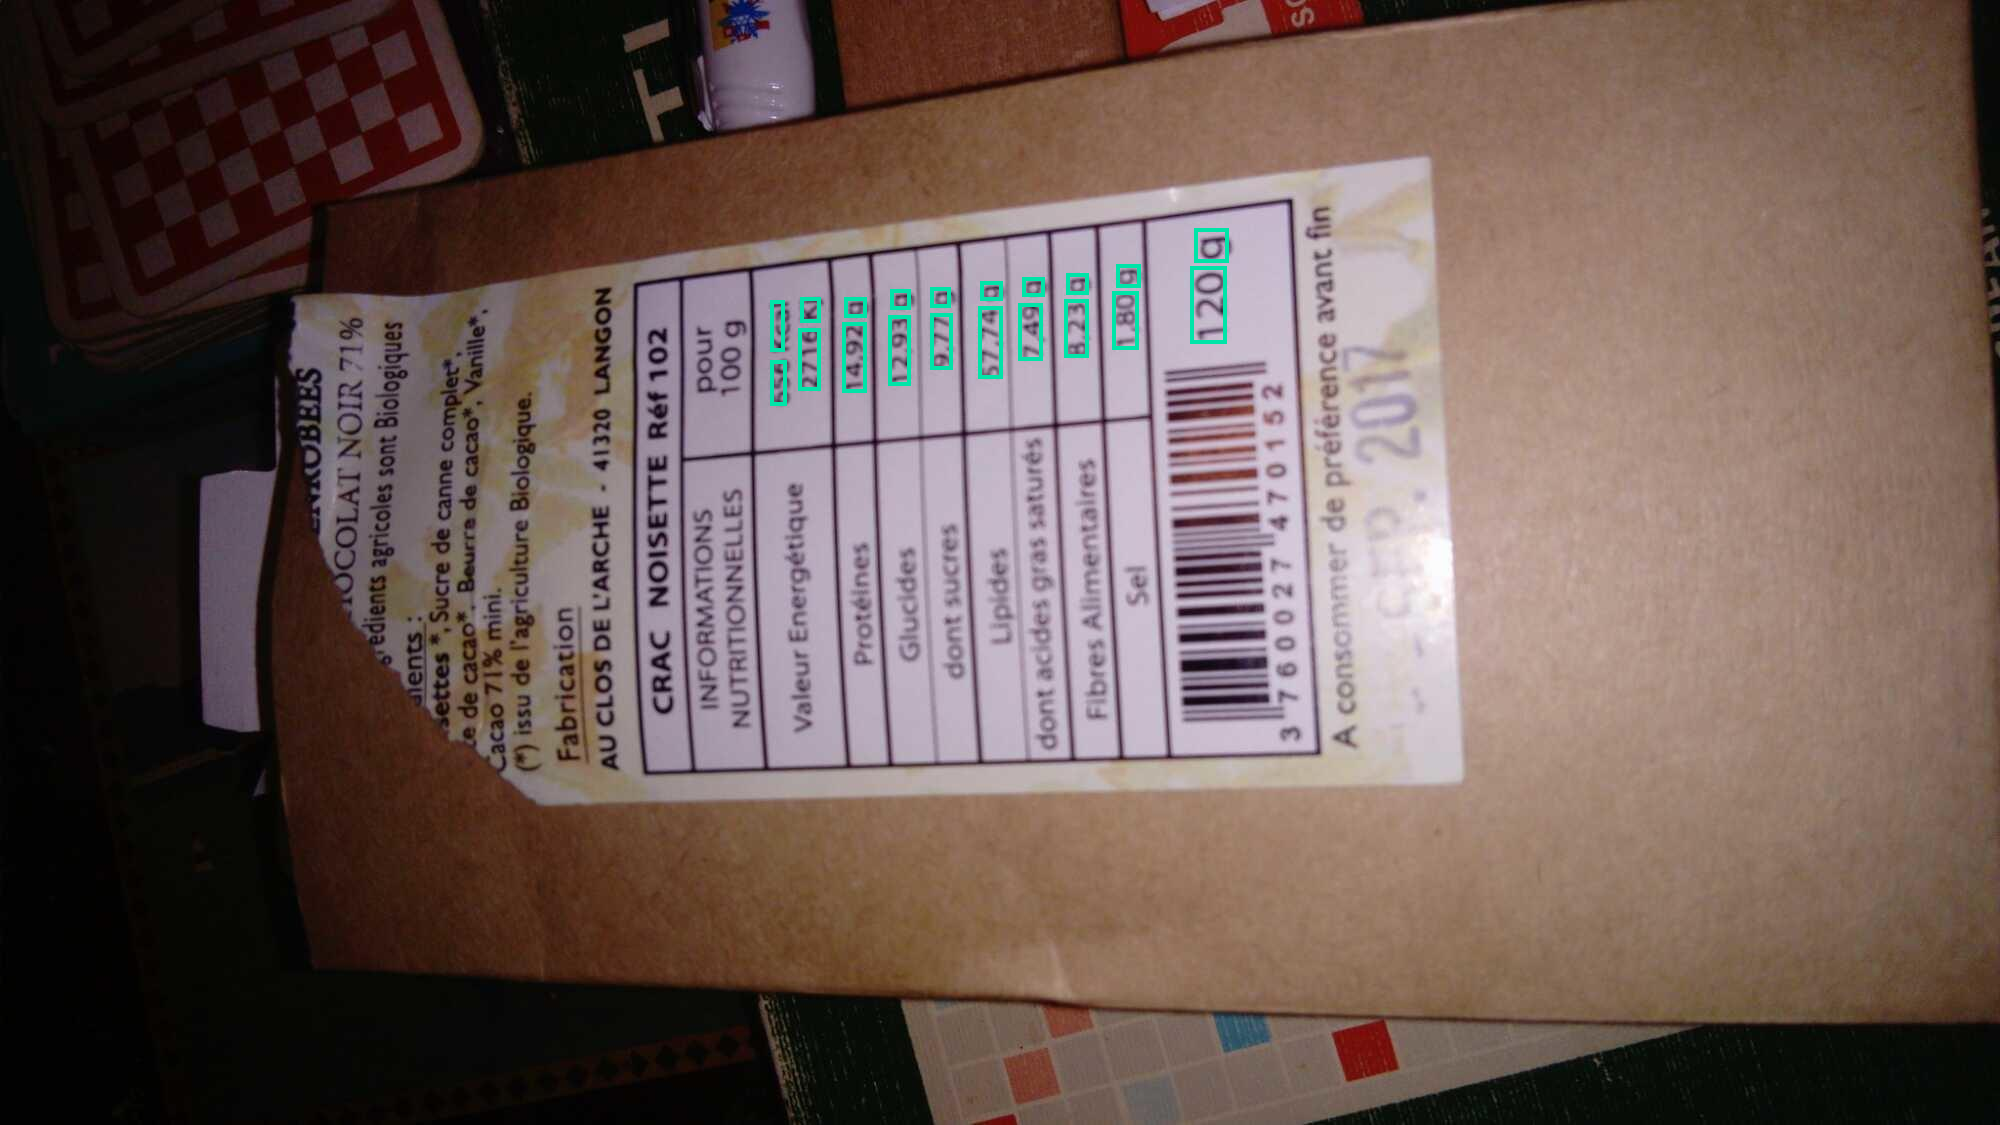

,OCR token,Gold BIO tag,Predicted BIO tag
0,ENKOBEES\n,O,O
1,OCOLAT,O,O
2,NOIR,O,O
3,71,O,O
4,%,O,O
...,...,...,...
105,SEP,O,O
106,.,O,O
107,2017\n,O,O
108,*\n,O,O


Normalized structured output:


,label,start,end,nutrient,basis,text,raw_text,raw_tokens,mean_token_confidence,parse_status,uncertainty_reasons,value,unit,qualifier,parsed_text,normalized_value,normalized_unit
0,ENERGY_KCAL_100G,76,78,energy,per_100g,656 Kcal,656 Kcal,"[656 , Kcal\n]",0.998865,parsed,[],656.00,kcal,None,656 Kcal,656.000000,kcal
1,ENERGY_KJ_100G,78,80,energy,per_100g,2716 KJ,2716 KJ,"[2716 , KJ\n]",0.998913,parsed,[],2716.00,kj,None,2716 KJ,649.139579,kcal
2,FAT_100G,80,82,fat,per_100g,"14,92 g","14,92 g","[14,92 , g\n]",0.997719,parsed,[],14.92,g,None,"14,92 g",14.920000,g
3,SATURATED_FAT_100G,82,84,saturated_fat,per_100g,"12,93 g","12,93 g","[12,93 , g\n]",0.998440,parsed,[],12.93,g,None,"12,93 g",12.930000,g
4,SUGARS_100G,88,90,sugars,per_100g,"7,49 g","7,49 g","[7,49 , g\n]",0.997840,parsed,[],7.49,g,None,"7,49 g",7.490000,g


Uncertain parsed spans:


,label,start,end,nutrient,basis,text,raw_text,raw_tokens,mean_token_confidence,parse_status,uncertainty_reasons,value,unit,qualifier,parsed_text,normalized_value,normalized_unit,duplicate_entity,duplicate_values_conflict
0,PROTEINS_100G,90,91,proteins,per_100g,"8,23","8,23","[8,23 ]",0.967979,uncertain,[unit_missing_or_not_read],8.23,None,NaN,"8,23",NaN,NaN,NaN,NaN
1,FIBER_100G,91,92,fiber,per_100g,g,g,[g\n],0.508429,uncertain,[no_numeric_value],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CARBOHYDRATES_100G,84,86,carbohydrates,per_100g,"9,77 g","9,77 g","[9,77 , g\n]",0.805593,uncertain,[duplicate_field_conflicting_values],9.77,g,NaN,"9,77 g",9.77,g,True,True
3,CARBOHYDRATES_100G,86,88,carbohydrates,per_100g,"57,74 g","57,74 g","[57,74 , g\n]",0.998580,uncertain,[duplicate_field_conflicting_values],57.74,g,NaN,"57,74 g",57.74,g,True,True
4,SALT_100G,92,94,salt,per_100g,"1,80 g","1,80 g","[1,80 , g\n]",0.975317,uncertain,[duplicate_field_conflicting_values],1.80,g,NaN,"1,80 g",1.80,g,True,True
5,SALT_100G,94,96,salt,per_100g,120 g,120 g,"[120 , g\n]",0.971604,uncertain,[duplicate_field_conflicting_values],120.00,g,NaN,120 g,120.00,g,True,True


In [15]:
if records and results:
    preview_index = 0
    record, prediction = records[preview_index], results[preview_index]
    print('Barcode:', record['barcode'], '| source test index:', record['source_index'],
          '| image size:', record['image'].size,
          '| inference windows:', prediction['inference_windows'],
          '| token coverage:', f"{prediction['covered_token_count']}/{prediction['token_count']}",
          '| inference seconds:', round(prediction['inference_seconds'], 3),
          '| process RSS after MB:', round(prediction['process_rss_after_mb'], 1) if prediction.get('process_rss_after_mb') is not None else None,
          '| process RSS delta MB:', round(prediction['process_rss_delta_mb'], 1) if prediction.get('process_rss_delta_mb') is not None else None,
          '| available RAM delta MB:', round(prediction['available_ram_delta_mb'], 1) if prediction.get('available_ram_delta_mb') is not None else None,
          '| cache hit:', prediction['cache_hit'])
    display(draw_prediction_boxes(record['image'], record['bboxes'], prediction['predicted_labels']))
    display(pd.DataFrame({
        'OCR token': record['tokens'],
        'Gold BIO tag': prediction['gold_labels'],
        'Predicted BIO tag': prediction['predicted_labels'],
    }))
    print('Normalized structured output:')
    display(pd.DataFrame(prediction['structured_output']['parsed_fields']))
    print('Uncertain parsed spans:')
    display(pd.DataFrame(prediction['structured_output']['uncertain_fields']))
else:
    print('No prediction table or metrics: local inference did not complete.')

## 4. Evaluate model and compare the existing rule baseline

Fine-grained model precision/recall/F1 use exact BIO entity-span matches against the official tags, with all labels kept distinct. Token accuracy is computed across covered original token positions. The existing lexical OCR rule tagger predicts a different ontology (nutrient name/value/unit/basis), so comparing its raw labels to 71 fine-grained gold labels would be invalid. For a meaningful comparison, both model and rule predictions are projected to a shared coarse taxonomy: nutrient value tokens become `VALUE`, serving-size/basis tokens become `BASIS`, and other tokens become `O`. Both methods use the exact same original OCR tokens, boxes, ground truth, and covered token positions. Reported run metrics are actual local ONNX results only; the memory-blocked run below has no scores or latency to report.

EasyOCR is intentionally not mixed into this evaluation: it produces a different token sequence, and token-position metrics are invalid without verified OCR-to-dataset alignment.

In [6]:
if records and results:
    gold_fine, pred_fine, gold_coarse, model_coarse, rule_coarse = [], [], [], [], []
    coverage_masks = []
    for record, result in zip(records, results):
        gold = [BIO_LABELS[int(tag)] for tag in record['ner_tags']]
        predicted = result['predicted_labels']
        gold_fine.append(gold)
        pred_fine.append(predicted)
        coverage_masks.append(result['coverage_mask'])
        gold_coarse.append(to_coarse_bio(gold))
        model_coarse.append(to_coarse_bio(predicted))
        rule_coarse.append(rule_baseline_coarse_bio(record['tokens'], record['bboxes'], record['image'].size))

    fine_metrics = evaluate_sequences(gold_fine, pred_fine, aligned=True, coverage_masks=coverage_masks)
    model_coarse_metrics = evaluate_sequences(gold_coarse, model_coarse, aligned=True, coverage_masks=coverage_masks)
    rule_coarse_metrics = evaluate_sequences(gold_coarse, rule_coarse, aligned=True, coverage_masks=coverage_masks)
    comparison = pd.DataFrame([
        {'method': MODEL_ID + ' (fine-grained)', **fine_metrics},
        {'method': MODEL_ID + ' (coarse projection)', **model_coarse_metrics},
        {'method': 'existing rule baseline (same coarse projection)', **rule_coarse_metrics},
    ])
    display(comparison)
    mean_seconds = sum(x['inference_seconds'] for x in results) / len(results)
    rss_after = [x['process_rss_after_mb'] for x in results if x.get('process_rss_after_mb') is not None]
    rss_delta = [x['process_rss_delta_mb'] for x in results if x.get('process_rss_delta_mb') is not None]
    available_delta = [x['available_ram_delta_mb'] for x in results if x.get('available_ram_delta_mb') is not None]
    print({
        'successful_images': len(results),
        'failures': evaluation_run.get('failures', []),
        'mean_inference_seconds_per_image': mean_seconds,
        'mean_process_rss_after_mb': sum(rss_after) / len(rss_after) if rss_after else None,
        'peak_process_rss_mb': max(rss_after) if rss_after else None,
        'mean_process_rss_delta_mb': sum(rss_delta) / len(rss_delta) if rss_delta else None,
        'mean_available_ram_delta_mb': sum(available_delta) / len(available_delta) if available_delta else None,
        'token_coverage': fine_metrics['token_coverage'],
        'gold_entity_coverage': fine_metrics['gold_entity_coverage'],
    })
    error_frame = pd.DataFrame(error_rows)
    if not error_frame.empty:
        print('Actual token disagreements by category:')
        display(error_frame['error_type'].value_counts().rename_axis('error_type').reset_index(name='count'))
        display(error_frame.head(30))
    else:
        print('No token disagreements in completed aligned spans.')

    # Parsing/duplicate ambiguity counts are diagnostics, not corrected labels.
    parsed_uncertainties = [
        field
        for result in results
        for field in result['structured_output']['uncertain_fields']
    ]
    print('Structured parser uncertainties:', len(parsed_uncertainties))
    if parsed_uncertainties:
        display(pd.DataFrame(parsed_uncertainties).head(30))

    bundle_path = layoutlm_bio.save_prediction_bundle(
        records, results,
        runtime_info=runtime_details,
        fine_metrics=fine_metrics,
        coarse_model_metrics=model_coarse_metrics,
        coarse_rule_metrics=rule_coarse_metrics,
        coarse_rule_labels=rule_coarse,
        evaluation_metadata={
            'seed': EVALUATION_SEED,
            'requested_images': EVALUATION_IMAGE_COUNT,
            'official_test_rows': evaluation_run['official_test_rows'],
            'selected_source_indices': evaluation_run['selected_source_indices'],
            'failures': evaluation_run['failures'],
        },
        output_path=ROOT / 'data' / 'part2_cache' / 'layoutlm_bio' / 'latest_test_bundle.json',
    )
    print('Saved dashboard-ready local result bundle:', bundle_path)
else:
    print('No precision, recall, F1, token accuracy, latency, or RAM-consumption metrics: local inference did not complete.')

,method,precision,recall,f1,true_positive_spans,predicted_spans,gold_spans,token_accuracy,token_support,covered_gold_spans,total_gold_spans,gold_entity_coverage,token_coverage
0,openfoodfacts/nutrition-extractor (fine-grained),0.926267,0.952607,0.939252,201,217,211,0.985816,1551,211,211,1.0,1.0
1,openfoodfacts/nutrition-extractor (coarse proj...,0.976744,0.995261,0.985915,210,215,211,0.995487,1551,211,211,1.0,1.0
2,existing rule baseline (same coarse projection),0.467967,0.796209,0.589474,168,359,211,0.837524,1551,211,211,1.0,1.0


{'successful_images': 20, 'failures': [], 'mean_inference_seconds_per_image': 3.2631126749999795, 'mean_process_rss_after_mb': 2035.4033203125, 'peak_process_rss_mb': 2078.140625, 'mean_process_rss_delta_mb': 3.3369140625, 'mean_available_ram_delta_mb': -12.586328125, 'token_coverage': 1.0, 'gold_entity_coverage': 1.0}
Actual token disagreements by category:


,error_type,count
0,wrong_entity_or_basis_label,15
1,false_positive_entity,6
2,bio_boundary_mismatch,1


,barcode,image_path,token_index,ocr_token,gold_label,predicted_label,error_type,context,ocr_text_independently_verified
0,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,80,"14,92",B-PROTEINS_100G,B-FAT_100G,wrong_entity_or_basis_label,"656 Kcal\n 2716 KJ\n 14,92 g\n 12,93 g\n 9...",False
1,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,81,g\n,I-PROTEINS_100G,I-FAT_100G,wrong_entity_or_basis_label,"Kcal\n 2716 KJ\n 14,92 g\n 12,93 g\n 9,77 g\n",False
2,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,82,"12,93",B-CARBOHYDRATES_100G,B-SATURATED_FAT_100G,wrong_entity_or_basis_label,"2716 KJ\n 14,92 g\n 12,93 g\n 9,77 g\n 57,74",False
3,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,83,g\n,I-CARBOHYDRATES_100G,I-SATURATED_FAT_100G,wrong_entity_or_basis_label,"KJ\n 14,92 g\n 12,93 g\n 9,77 g\n 57,74 g\n",False
4,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,84,"9,77",B-SUGARS_100G,B-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"14,92 g\n 12,93 g\n 9,77 g\n 57,74 g\n 7,49",False
5,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,85,g\n,I-SUGARS_100G,I-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"g\n 12,93 g\n 9,77 g\n 57,74 g\n 7,49 g\n",False
6,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,86,"57,74",B-FAT_100G,B-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"12,93 g\n 9,77 g\n 57,74 g\n 7,49 g\n 8,23",False
7,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,87,g\n,I-FAT_100G,I-CARBOHYDRATES_100G,wrong_entity_or_basis_label,"g\n 9,77 g\n 57,74 g\n 7,49 g\n 8,23 g\n",False
8,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,88,"7,49",B-SATURATED_FAT_100G,B-SUGARS_100G,wrong_entity_or_basis_label,"9,77 g\n 57,74 g\n 7,49 g\n 8,23 g\n 1,80",False
9,3760027470152,C:\Users\SaniaJawaid\Documents\projects\practi...,89,g\n,I-SATURATED_FAT_100G,I-SUGARS_100G,wrong_entity_or_basis_label,"g\n 57,74 g\n 7,49 g\n 8,23 g\n 1,80 g\n",False


Structured parser uncertainties: 38


,label,start,end,nutrient,basis,text,raw_text,raw_tokens,mean_token_confidence,parse_status,uncertainty_reasons,value,unit,qualifier,parsed_text,normalized_value,normalized_unit,duplicate_entity,duplicate_values_conflict
0,PROTEINS_100G,90,91,proteins,per_100g,"8,23","8,23","[8,23 ]",0.967979,uncertain,[unit_missing_or_not_read],8.2300,None,NaN,"8,23",NaN,NaN,NaN,NaN
1,FIBER_100G,91,92,fiber,per_100g,g,g,[g\n],0.508429,uncertain,[no_numeric_value],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CARBOHYDRATES_100G,84,86,carbohydrates,per_100g,"9,77 g","9,77 g","[9,77 , g\n]",0.805593,uncertain,[duplicate_field_conflicting_values],9.7700,g,NaN,"9,77 g",9.770000,g,True,True
3,CARBOHYDRATES_100G,86,88,carbohydrates,per_100g,"57,74 g","57,74 g","[57,74 , g\n]",0.998580,uncertain,[duplicate_field_conflicting_values],57.7400,g,NaN,"57,74 g",57.740000,g,True,True
4,SALT_100G,92,94,salt,per_100g,"1,80 g","1,80 g","[1,80 , g\n]",0.975317,uncertain,[duplicate_field_conflicting_values],1.8000,g,NaN,"1,80 g",1.800000,g,True,True
5,SALT_100G,94,96,salt,per_100g,120 g,120 g,"[120 , g\n]",0.971604,uncertain,[duplicate_field_conflicting_values],120.0000,g,NaN,120 g,120.000000,g,True,True
6,SUGARS_100G,70,72,sugars,per_100g,sucres:0.9 g;,sucres:0.9 g;,"[sucres:0.9 , g; ]",0.998558,uncertain,[unparsed_letters_near_numeric_value],0.9000,g,NaN,0.9 g,0.900000,g,NaN,NaN
7,ENERGY_KJ_SERVING,28,30,energy,per_serving,(454 k),(454 k),"[(454 , k) ]",0.996072,uncertain,[unparsed_letters_near_numeric_value],454.0000,kj,NaN,454,108.508604,kcal,NaN,NaN
8,ENERGY_KCAL_SERVING,30,32,energy,per_serving,/109 kcal-5,/109 kcal-5,"[/109 , kcal-5 ]",0.997820,uncertain,[multiple_numeric_values_in_one_BIO_span],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,CARBOHYDRATES_SERVING,65,67,carbohydrates,per_serving,(0 g-0,(0 g-0,"[(0 , g-0 ]",0.991534,uncertain,[multiple_numeric_values_in_one_BIO_span],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Saved dashboard-ready local result bundle: C:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\data\part2_cache\layoutlm_bio\latest_test_bundle.json


## 5. Offline smoke tests

These checks validate BIO label projection, entity extraction, the shared-label rule mapping, and evaluation guardrails without loading or downloading model weights.

In [12]:
import subprocess

assert to_coarse_bio(["O", "B-FAT_100G", "I-FAT_100G", "B-SERVING_SIZE"]) == [
    "O", "B-VALUE", "I-VALUE", "B-BASIS",
]
smoke_gold = [["O", "B-VALUE", "I-VALUE", "O"]]
assert evaluate_sequences(smoke_gold, smoke_gold, aligned=True)["f1"] == 1.0

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")],
    cwd=ROOT,
    capture_output=True,
    text=True,
)
print(result.stdout)
if result.returncode:
    print(result.stderr)
    raise RuntimeError(f"Project tests failed with exit code {result.returncode}.")
print("Pure BIO helper smoke checks passed. Model weights were not accessed.")

..................................................                       [100%]
50 passed in 3.11s

Pure BIO helper smoke checks passed. Model weights were not accessed.


## 6. End-to-end EasyOCR → local ONNX smoke test

This exercises the uploaded-image path on one cached image, without using its supplied tokens or annotations. It is an integration check, not an unseen-image accuracy benchmark. Set `UPLOAD_IMAGE_PATH` to an independent local image to try a real upload. Only already-cached EasyOCR weights are used; no gold BIO metrics are computed for this OCR tokenization.

In [11]:
import part2.ocr as ocr_adapter
ocr_adapter = importlib.reload(ocr_adapter)
layoutlm_bio = importlib.reload(layoutlm_bio)
UPLOAD_IMAGE_PATH = None  # Set a local image path; None uses the initial one-image smoke sample.
upload_smoke = None
if model is not None and (UPLOAD_IMAGE_PATH or records):
    ram_gb = layoutlm_bio.available_ram_bytes() / 1024**3
    if ram_gb < 0.75:
        print(f'EasyOCR smoke test skipped safely: {ram_gb:.2f} GiB available.')
    else:
        upload_smoke = layoutlm_bio.predict_uploaded_image(
            Path(UPLOAD_IMAGE_PATH) if UPLOAD_IMAGE_PATH else Path(dataset[0]['image_path']),
            model=model, processor=processor, id2label=model_id2label,
            cache_dir=INFERENCE_DIR, easyocr_model_dir=ROOT / 'models' / 'easyocr',
            ocr_cache_dir=ROOT / 'data' / 'part2_cache' / 'ocr',
        )
        if upload_smoke.get('ocr_error'):
            print('Actual OCR failure:', upload_smoke['ocr_error'])
        else:
            assert upload_smoke['gold_available'] is False
            assert upload_smoke['prediction']['gold_labels'] is None
            print({'ocr_tokens': len(upload_smoke['tokens']),
                   'covered_tokens': upload_smoke['prediction']['covered_token_count'],
                   'ocr_seconds': upload_smoke['ocr_elapsed_seconds'],
                   'onnx_seconds': upload_smoke['prediction']['inference_seconds'],
                   'parsed_fields': len(upload_smoke['structured_output']['parsed_fields']),
                   'uncertain_fields': len(upload_smoke['structured_output']['uncertain_fields']),
                   'quantization': False})
            print(upload_smoke['warning'])
            display(pd.DataFrame({'OCR token': upload_smoke['tokens'], 'Predicted BIO': upload_smoke['prediction']['predicted_labels']}))
else:
    print('No loaded model or local image; EasyOCR integration was not run.')

c:\Users\SaniaJawaid\Documents\projects\practice\study\.venv-1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


{'ocr_tokens': 82, 'covered_tokens': 82, 'ocr_seconds': 2.348885599999903, 'onnx_seconds': 3.2282907999997406, 'parsed_fields': 4, 'uncertain_fields': 8, 'quantization': False}
EasyOCR words share their parent detection boxes and have no gold alignment; do not report BIO or field accuracy. Rotation, blur and OCR grouping can prevent extraction.


,OCR token,Predicted BIO
0,mndiens:,O
1,Fillets,O
2,concentré,O
3,",",O
4,de,O
...,...,...
77,fin,O
78,9Oce,O
79,[ox,O
80,'vorsur,O


## 7. Separate API metadata check and saved measured report

Query at most 10 evaluated barcodes, cache the actual responses, and keep these comparisons separate from BIO metrics. Product API values are mutable metadata, not visual gold. The saved report also includes exact field tuples derived from official annotations, actual error examples, parser uncertainty counts, and the EasyOCR integration outcome.

In [13]:
import json
from collections import Counter
layoutlm_bio = importlib.reload(layoutlm_bio)
api_comparisons = []
for record, prediction in zip(records[:10], results[:10]):
    barcode = str(record['barcode'])
    try:
        response = layoutlm_bio.fetch_openfoodfacts_product(
            barcode, cache_dir=ROOT / 'data' / 'part2_cache' / 'openfoodfacts_products',
        )
        api_comparisons.append({'barcode': barcode, **layoutlm_bio.compare_fields_to_off_metadata(prediction['structured_output'], response)})
    except Exception as error:
        api_comparisons.append({'barcode': barcode, 'status': f'{type(error).__name__}: {error}', 'reference_is_visual_gold': False})
display(pd.DataFrame([{key: value for key, value in item.items() if key != 'comparisons'} for item in api_comparisons]))
if results and evaluation_run.get('metrics'):
    field_rows = evaluation_run['field_comparisons']
    matched = sum(row['true_positive'] for row in field_rows)
    predicted_count = sum(row['predicted_fields'] for row in field_rows)
    gold_count = sum(row['gold_fields'] for row in field_rows)
    field_p = matched / predicted_count if predicted_count else 0
    field_r = matched / gold_count if gold_count else 0
    report = {
        'inference_schema_version': layoutlm_bio.INFERENCE_SCHEMA_VERSION,
        'seed': EVALUATION_SEED, 'requested_images': EVALUATION_IMAGE_COUNT,
        'successful_images': len(results), 'failures': evaluation_run['failures'],
        'selected_source_indices': evaluation_run['selected_source_indices'],
        'metrics': evaluation_run['metrics'],
        'field_tuple_metrics': {'precision': field_p, 'recall': field_r,
            'f1': 2*field_p*field_r/(field_p+field_r) if field_p+field_r else 0,
            'matched': matched, 'predicted_fields': predicted_count, 'parseable_gold_fields': gold_count,
            'excluded_uncertain_gold_spans': sum(row['gold_uncertain_spans'] for row in field_rows)},
        'mean_inference_seconds': sum(row['inference_seconds'] for row in results)/len(results),
        'error_category_counts': dict(Counter(row['error_type'] for row in error_rows)),
        'error_examples': error_rows, 'field_comparisons': field_rows,
        'api_metadata_comparisons_not_visual_gold': api_comparisons,
        'easyocr_smoke': {'gold_available': False,
            'ocr_error': upload_smoke.get('ocr_error'),
            'token_count': len(upload_smoke.get('tokens', [])),
            'parsed_fields': len(upload_smoke.get('structured_output', {}).get('parsed_fields', []))} if upload_smoke else None,
    }
    report_path = ROOT / 'reports' / 'part2' / 'bio_measured_evaluation.json'
    report_path.parent.mkdir(parents=True, exist_ok=True)
    report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8')
    print('Measured field tuple metrics:', report['field_tuple_metrics'])
    print('Saved actual measurements:', report_path)

,barcode,reference_source,reference_is_visual_gold,product_name,api_reference_fields_available,model_fields_with_compatible_api_reference,exact_value_count,exact_value_accuracy,field_tuple_precision,field_tuple_recall,field_tuple_f1,field_tuple_metric_note
0,3760027470152,Open Food Facts product API,False,Crac Noisettes,10,5,1,0.200000,0.200000,0.100000,0.133333,Exact nutrient+basis+unit+value tuple against ...
1,3576620008209,Open Food Facts product API,False,Pâte de campagne,11,7,6,0.857143,0.857143,0.545455,0.666667,Exact nutrient+basis+unit+value tuple against ...
2,5400210432861,Open Food Facts product API,False,Apero gouda jeune,9,8,7,0.875000,0.875000,0.777778,0.823529,Exact nutrient+basis+unit+value tuple against ...
3,8437013754477,Open Food Facts product API,False,Jamón serrano,9,8,6,0.750000,0.750000,0.666667,0.705882,Exact nutrient+basis+unit+value tuple against ...
4,8410573103169,Open Food Facts product API,False,Patatas fritas sabor a jamón iberico,9,8,6,0.750000,0.750000,0.666667,0.705882,Exact nutrient+basis+unit+value tuple against ...
5,8433329104128,Open Food Facts product API,False,Mantequilla sin sal,9,5,4,0.800000,0.800000,0.444444,0.571429,Exact nutrient+basis+unit+value tuple against ...
6,2968460002850,Open Food Facts product API,False,Hamburguesa de vacuno y cerdo,9,8,3,0.375000,0.375000,0.333333,0.352941,Exact nutrient+basis+unit+value tuple against ...
7,4056489232124,Open Food Facts product API,False,Herring fillets,20,8,7,0.875000,0.875000,0.350000,0.500000,Exact nutrient+basis+unit+value tuple against ...
8,3383810002646,Open Food Facts product API,False,Nectar multifruits,7,7,2,0.285714,0.285714,0.285714,0.285714,Exact nutrient+basis+unit+value tuple against ...
9,3661945710026,Open Food Facts product API,False,Gingembre confit,10,7,6,0.857143,0.857143,0.600000,0.705882,Exact nutrient+basis+unit+value tuple against ...


Measured field tuple metrics: {'precision': 0.9720670391061452, 'recall': 0.93048128342246, 'f1': 0.9508196721311476, 'matched': 174, 'predicted_fields': 179, 'parseable_gold_fields': 187, 'excluded_uncertain_gold_spans': 24}
Saved actual measurements: C:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\part2\bio_measured_evaluation.json


In [10]:
# Coverage regression: the original three-image prefix previously covered only 391/453 words.
# This check is separate from the seeded 20-image benchmark above.
if model is not None and layoutlm_bio.available_ram_bytes() / 1024**3 >= 0.75:
    regression_dataset = HuggingFaceNutritionDataset(DatasetConfig(
        split='test', subset_size=3, batch_size=1,
        image_cache=ROOT / 'data' / 'part2_cache' / 'images',
    ))
    regression_rows = []
    for index in range(3):
        if layoutlm_bio.available_ram_bytes() / 1024**3 < 0.75:
            print('Coverage regression stopped safely due to RAM.')
            break
        item = regression_dataset[index]
        predicted = layoutlm_bio.predict_record(
            item, model=model, processor=processor, id2label=model_id2label, cache_dir=INFERENCE_DIR,
        )
        regression_rows.append({'barcode': item['barcode'], 'tokens': predicted['token_count'],
            'covered': predicted['covered_token_count'], 'windows': predicted['inference_windows']})
    display(pd.DataFrame(regression_rows))
    print('Original prefix coverage:', sum(row['covered'] for row in regression_rows), '/', sum(row['tokens'] for row in regression_rows))
else:
    print('Coverage regression skipped: model unavailable or RAM below continuation limit.')

,barcode,tokens,covered,windows
0,3700821000223,87,87,1
1,06174988,242,242,2
2,7613379505774,124,124,1


Original prefix coverage: 453 / 453


## 8. Complete field accuracy and actual error review

The existing manually reviewed product 241013128 supplies 16 numerical fields and a transcription. Evaluate EasyOCR → ONNX and the existing rules against this reference, without changing gold files or inventing BIO alignment. This is a one-image validation fixture, not a held-out population benchmark. Exact numerical accuracy is conditional on matching nutrient/basis/unit keys; missing fields affect recall separately. kJ/kcal declarations remain separate. Parser suspicions in dataset examples are not called confirmed OCR errors.

The second cell re-analyses the **saved** 20-image predictions without re-running inference. Its timestamps describe analysis of cached outputs, not new model measurements.

In [16]:
import importlib
import part2.bio_review as bio_review
bio_review = importlib.reload(bio_review)
import part2.layoutlm_bio as layoutlm_bio
layoutlm_bio = importlib.reload(layoutlm_bio)
manual_review = None
if globals().get('model') is not None:
    try:
        manual_review = bio_review.run_manual_reference_review(
            ROOT, model=model, processor=processor, id2label=model_id2label,
        )
        print('Manual image review status:', manual_review['status'])
        if manual_review.get('field_metrics'):
            display(pd.DataFrame([{'method': name, **{key: value for key, value in manual_review[name].items() if not isinstance(value, list)}}
                                  for name in ['field_metrics', 'rule_field_metrics_same_ocr']]))
            print('Actual OCR CER/WER:', manual_review['ocr_metrics'])
            print('Parsing failures:', manual_review['parse_failure_count'])
            display(pd.DataFrame(manual_review['field_metrics']['comparisons']))
            display(pd.DataFrame(manual_review['ocr_difference_examples']).head(30))
        else:
            print('No accuracy reported:', manual_review.get('ocr_error'))
    except layoutlm_bio.InsufficientResourcesError as error:
        print('Safely paused:', error)
else:
    print('No resident model. Run the existing resource-gated load cell before the manual review.')

c:\Users\SaniaJawaid\Documents\projects\practice\study\.venv-1\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Manual image review status: completed_single_manual_reference


,method,reference_source,true_positive,false_positive,false_negative,predicted_fields,gold_fields,field_precision,field_recall,field_f1,exact_value_matches,comparable_value_fields,exact_value_accuracy,exact_value_accuracy_note
0,field_metrics,existing manually reviewed gold files from par...,5,0,11,5,16,1.0,0.3125,0.476190,5,5,1.0,Exact value AND qualifier on matching nutrient...
1,rule_field_metrics_same_ocr,existing manually reviewed gold files from par...,1,1,15,2,16,0.5,0.0625,0.111111,1,1,1.0,Exact value AND qualifier on matching nutrient...


Actual OCR CER/WER: {'status': 'measured_on_manual_references', 'support': 1, 'cer': 0.10091743119266056, 'wer': 0.46153846153846156}
Parsing failures: 14


,nutrient,basis,unit,reference_value,predicted_value,reference_qualifier,predicted_qualifier,status
0,carbohydrates,per_100g,g,32.00,NaN,None,None,missing_prediction
1,carbohydrates,per_serving,g,28.80,NaN,None,None,missing_prediction
2,energy,per_100g,kcal,237.00,237.00,None,None,exact_match
3,energy,per_100g,kj,992.00,NaN,None,None,missing_prediction
4,energy,per_serving,kcal,213.00,213.00,None,None,exact_match
5,energy,per_serving,kj,893.00,893.00,None,None,exact_match
6,fat,per_100g,g,9.50,NaN,None,None,missing_prediction
7,fat,per_serving,g,8.60,NaN,None,None,missing_prediction
8,proteins,per_100g,g,4.60,NaN,None,None,missing_prediction
9,proteins,per_serving,g,4.10,NaN,None,None,missing_prediction


,operation,reference,ocr,reference_start,ocr_start,note
0,replace,g,9,5,5,Text/order difference against manual reference...
1,replace,992 kj,992k /,8,8,Text/order difference against manual reference...
2,replace,ar ( 1 ) -,ari _,18,18,Text/order difference against manual reference...
3,replace,5 g,59,27,24,Text/order difference against manual reference...
4,replace,g,9,37,33,Text/order difference against manual reference...
5,replace,g,9,41,37,Text/order difference against manual reference...
6,replace,7 g,7g,47,43,Text/order difference against manual reference...
7,replace,protéines,proteines,50,45,Text/order difference against manual reference...
8,replace,6 g,69,53,48,Text/order difference against manual reference...
9,replace,36 g .,36g,59,53,Text/order difference against manual reference...


In [17]:
# Offline re-analysis only: do not reload weights or call the model for the 20-image set.
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import importlib
import json
import pandas as pd
import part2.layoutlm_bio as layoutlm_bio
import part2.bio_review as bio_review
layoutlm_bio = importlib.reload(layoutlm_bio)
bio_review = importlib.reload(bio_review)
review_root = globals().get('ROOT', Path.cwd()).resolve()
if review_root.name == 'part2':
    review_root = review_root.parent
bundle_file = review_root / 'data/part2_cache/layoutlm_bio/latest_test_bundle.json'
saved_bundle = json.loads(bundle_file.read_text(encoding='utf-8'))
assert saved_bundle['inference_schema_version'] == layoutlm_bio.INFERENCE_SCHEMA_VERSION
saved_samples = saved_bundle['samples']
field_reviews = [dict(barcode=sample['barcode'], **layoutlm_bio.compare_fields_to_gold(
    sample['tokens'], sample['gold_labels'], sample['predicted_labels'])) for sample in saved_samples]
field_aggregate = bio_review.summarize_field_evaluations(field_reviews)
parser_review = bio_review.prediction_diagnostics(saved_samples, saved_samples)
bio_errors = layoutlm_bio.analyze_bio_errors(saved_samples, saved_samples)
api_review = []
for sample in saved_samples[:10]:
    response = layoutlm_bio.fetch_openfoodfacts_product(sample['barcode'], cache_dir=review_root / 'data/part2_cache/openfoodfacts_products')
    api_review.append(dict(barcode=sample['barcode'], from_cache=response.get('from_cache'),
        **layoutlm_bio.compare_fields_to_off_metadata(sample['structured_output'], response)))
completion_report = {
    'analysis_at_utc': datetime.now(timezone.utc).isoformat(),
    'provenance': 'Offline analysis of saved predictions; original inference timing remains historical, not newly measured.',
    'source_bundle_sha256': hashlib.sha256(bundle_file.read_bytes()).hexdigest(),
    'sample_count': saved_bundle['sample_count'],
    'sampling': saved_bundle['evaluation_metadata'],
    'field_summary': field_aggregate, 'field_comparisons': field_reviews,
    'parser_and_coverage_diagnostics': parser_review,
    'bio_error_examples': bio_errors,
    'separate_api_metadata_not_visual_gold': api_review,
    'manual_reference_review': bio_review.load_manual_reference_review(review_root),
}
completion_file = review_root / 'reports/part2/bio_remaining_tasks_review.json'
completion_file.write_text(json.dumps(completion_report, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Re-analysis of cached predictions, not new inference:', field_aggregate)
display(pd.DataFrame([{'reason': key, 'count': value} for key, value in parser_review['reason_counts'].items()]))
print('Actual BIO disagreement examples:', len(bio_errors))
print('Separate API product references:', len(api_review))
print('Saved:', completion_file)

Re-analysis of cached predictions, not new inference: {'true_positive': 174, 'false_positive': 5, 'false_negative': 13, 'predicted_fields': 179, 'gold_fields': 187, 'exact_value_matches': 174, 'comparable_value_fields': 178, 'gold_uncertain_spans': 24, 'predicted_uncertain_spans': 38, 'images': 20, 'field_precision': 0.9720670391061452, 'field_recall': 0.93048128342246, 'field_f1': 0.9508196721311476, 'exact_value_accuracy': 0.9775280898876404}


,reason,count
0,unit_missing_or_not_read,8
1,no_numeric_value,9
2,duplicate_field_conflicting_values,8
3,unparsed_letters_near_numeric_value,8
4,multiple_numeric_values_in_one_BIO_span,7


Actual BIO disagreement examples: 22
Separate API product references: 10
Saved: C:\Users\SaniaJawaid\Documents\projects\practice\study\nutrition_extraction_solution\reports\part2\bio_remaining_tasks_review.json


## Full matched cohort: 3,075 images (2,876 train + 199 test)

The full CPU inference worker is separate from the seeded 20-image evaluation above. It uses original dataset images, supplied OCR words, normalized boxes and the existing overlapping-window predictor; it does not rerun OCR, retrain, or use product metadata as gold. Eight unmatched images are excluded by exact barcode membership. Each completed image is checkpointed independently; failed/pending images are explicitly counted and are not scored as zero accuracy.

The following cell reads the latest saved progress and predictions without loading another model. Rerun it during/after execution to refresh results. Train scores are descriptive only, not evidence of held-out generalization. Official-test metrics are kept separate. The dashboard's **BIO Entity Tagging → Complete matched dataset** panel refreshes every 30 seconds. Restarting the separate runner resumes compatible checkpoints and retries failures, while preserving the original 20-image evaluation bundle.

In [18]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown

FULL_BIO_ROOT = Path.cwd().resolve()
while not (FULL_BIO_ROOT / 'app.py').exists() and FULL_BIO_ROOT != FULL_BIO_ROOT.parent:
    FULL_BIO_ROOT = FULL_BIO_ROOT.parent
FULL_BIO_OUTPUT = FULL_BIO_ROOT / 'outputs/full_cohort_bio'

def show_full_cohort_bio(image_key=None):
    summary_path = FULL_BIO_OUTPUT / 'summary.json'
    if not summary_path.exists():
        print('No checkpoint published yet. Start the separate full-cohort runner first.')
        return
    summary = json.loads(summary_path.read_text(encoding='utf-8'))
    display(pd.DataFrame([{name:summary[name] for name in ['status','target_images','completed_images','pending_images','failed_images','updated_at_utc']}]))
    if summary['completed_images'] != summary['target_images']:
        display(Markdown('**Partial run: these metrics cover completed images only, not all 3,075. Rerun this cell to refresh.**'))
    metrics = pd.DataFrame([dict(split=split, **value) for split,value in summary['metrics_by_split'].items()])
    metrics.loc[metrics['images'].eq(0), ['precision','recall','f1','token_accuracy']] = float('nan')
    display(metrics)
    print(summary['caveat'])
    if summary['completed_images']:
        results = pd.read_csv(FULL_BIO_OUTPUT / 'image_results.csv', dtype={'barcode':'string'})
        assert results['image_key'].is_unique
        assert results['token_coverage'].eq(1).all()
        display(results)
        key = image_key or results.iloc[-1]['image_key']
        sample = json.loads((FULL_BIO_OUTPUT/'samples'/f"{key.replace(':','_')}.json").read_text(encoding='utf-8'))
        prediction = sample['prediction']
        print('Selected image:', key, 'barcode:',sample['barcode'], 'split:',sample['split'])
        display(pd.DataFrame(dict(token_index=range(len(sample['tokens'])), ocr_token=sample['tokens'], gold_bio=prediction['gold_labels'], predicted_bio=prediction['predicted_labels'])))
        display(pd.DataFrame(prediction['structured_output'].get('parsed_fields', [])))
        display(prediction['structured_output'])
    if summary['failed_images']:
        display(pd.DataFrame(json.loads((FULL_BIO_OUTPUT/'failures.json').read_text(encoding='utf-8'))))
    return summary

full_cohort_progress = show_full_cohort_bio()
# Inspect a particular completed image with show_full_cohort_bio('test:0').

,status,target_images,completed_images,pending_images,failed_images,updated_at_utc
0,running,3075,16,3059,0,2026-10-30T14:01:48.481324+00:00


**Partial run: these metrics cover completed images only, not all 3,075. Rerun this cell to refresh.**

,split,images,true_positive_spans,predicted_spans,gold_spans,precision,recall,f1,token_support,token_accuracy
0,train,0,0,0,0,NaN,NaN,NaN,0,NaN
1,test,16,184,195,191,0.94359,0.963351,0.953368,1938,0.990712


Train scores are descriptive, not held-out generalization. Test selection is all matched official test rows. Supplied OCR; no OCR run. No metadata is used as gold.


,image_key,barcode,split,token_support,correct_tokens,true_positive_spans,predicted_spans,gold_spans,precision,recall,f1,token_accuracy,inference_seconds,inference_windows,cache_hit,token_coverage
0,test:0,3700821000223,test,87,86,8,9,8,0.888889,1.000000,0.941176,0.988506,3.312266,1,True,1.0
1,test:1,06174988,test,242,240,19,20,19,0.950000,1.000000,0.974359,0.991736,7.790894,2,True,1.0
2,test:2,7613379505774,test,124,124,19,19,19,1.000000,1.000000,1.000000,1.000000,4.869361,1,True,1.0
3,test:3,2642824003775,test,146,146,8,8,8,1.000000,1.000000,1.000000,1.000000,4.600292,1,False,1.0
4,test:4,3760038790034,test,138,138,8,8,8,1.000000,1.000000,1.000000,1.000000,3.953343,1,False,1.0
5,test:5,4018722344353,test,76,76,9,9,9,1.000000,1.000000,1.000000,1.000000,3.237814,1,False,1.0
6,test:6,3760027470152,test,110,97,3,11,9,0.272727,0.333333,0.300000,0.881818,3.181373,1,True,1.0
7,test:7,3576620008209,test,88,88,8,8,8,1.000000,1.000000,1.000000,1.000000,3.187059,1,True,1.0
8,test:8,5400210432861,test,133,133,19,19,19,1.000000,1.000000,1.000000,1.000000,4.050953,1,True,1.0
9,test:9,3444942009061,test,29,29,7,7,7,1.000000,1.000000,1.000000,1.000000,2.432818,1,False,1.0


Selected image: test:15 barcode: 3560071284305 split: test


,token_index,ocr_token,gold_bio,predicted_bio
0,0,"koolzaadolie*“,",O,O
1,1,knoflook**.,O,O
2,2,**Ingrediënten,O,O
3,3,afkomstig,O,O
4,4,uit,O,O
...,...,...,...,...
104,104,We\n,O,O
105,105,Sodium,O,O
106,106,/,O,O
107,107,Natrium\n,O,O


,label,start,end,nutrient,basis,text,raw_text,raw_tokens,mean_token_confidence,parse_status,uncertainty_reasons,value,unit,qualifier,parsed_text,normalized_value,normalized_unit
0,SERVING_SIZE,31,33,serving_size,per_serving,250 g,250 g,"[250 , g ]",0.997655,parsed,[],250.00,g,None,250 g,250.000000,g
1,ENERGY_KJ_SERVING,33,35,energy,per_serving,685 kJ,685 kJ,"[685 , kJ ]",0.998311,parsed,[],685.00,kj,None,685 kJ,163.718929,kcal
2,ENERGY_KCAL_100G,35,37,energy,per_100g,65 kcal,65 kcal,"[65 , kcal ]",0.999013,parsed,[],65.00,kcal,None,65 kcal,65.000000,kcal
3,ENERGY_KCAL_SERVING,37,39,energy,per_serving,163 kcal,163 kcal,"[163 , kcal ]",0.997683,parsed,[],163.00,kcal,None,163 kcal,163.000000,kcal
4,FAT_SERVING,39,41,fat,per_serving,"4,5 g","4,5 g","[4,5 , g\n]",0.997948,parsed,[],4.50,g,None,"4,5 g",4.500000,g
5,ENERGY_KJ_100G,46,48,energy,per_100g,274 kJ,274 kJ,"[274 , kJ\n]",0.998958,parsed,[],274.00,kj,None,274 kJ,65.487572,kcal
6,SATURATED_FAT_100G,58,60,saturated_fat,per_100g,"0,6 g","0,6 g","[0,6 , g ]",0.998810,parsed,[],0.60,g,None,"0,6 g",0.600000,g
7,SUGARS_100G,66,68,sugars,per_100g,"3,7 g","3,7 g","[3,7 , g ]",0.998959,parsed,[],3.70,g,None,"3,7 g",3.700000,g
8,FAT_100G,71,73,fat,per_100g,"1,8 g","1,8 g","[1,8 , g\n]",0.999168,parsed,[],1.80,g,None,"1,8 g",1.800000,g
9,SATURATED_FAT_SERVING,73,74,saturated_fat,per_serving,"1,5g","1,5g","[1,5g ]",0.998439,parsed,[],1.50,g,None,"1,5g",1.500000,g


{'schema_version': '5-adaptive-sliding-structured',
 'model_id': 'openfoodfacts/nutrition-extractor',
 'model_revision': '4c28d479f332339ffc367d9aae66036a4583127c',
 'model_license': 'cc-by-nc-sa-4.0',
 'barcode': '3560071284305',
 'image_path': 'C:\\Users\\SaniaJawaid\\Documents\\projects\\practice\\study\\nutrition_extraction_solution\\data\\part2_cache\\images\\d86a0a87a19354a94083f5f30b70ce6c8b80b81a715f047edf3777f5ccaf6e81.jpg',
 'raw_predictions': {'tokens': ['koolzaadolie*“, ',
   'knoflook**. ',
   '**Ingrediënten ',
   'afkomstig ',
   'uit ',
   'de ',
   'biologische ',
   "l'opt ",
   'enfa\n',
   'landbouw.\n',
   'et ',
   'd ',
   'Portion ',
   "d'1 ",
   'assiette ',
   '/\n',
   'Nutrition/Voeding ',
   'Valeurs ',
   'moyennes ',
   'pour:\n',
   'rest ',
   'Portie ',
   'van ',
   '1 ',
   'bordje ',
   'N°\n',
   'Gemiddelde ',
   'waarden ',
   'per: ',
   '100 ',
   'g ',
   '250 ',
   'g ',
   '685 ',
   'kJ ',
   '65 ',
   'kcal ',
   '163 ',
   'kcal ',
   '4

In [19]:
# Validate UI rendering without loading model weights or interrupting the worker.
import subprocess
import sys
full_bio_ui_check = subprocess.run(
    [str(FULL_BIO_ROOT / '.venv/Scripts/python.exe'), str(FULL_BIO_ROOT / 'scripts/validate_full_cohort_dashboard.py')],
    cwd=FULL_BIO_ROOT, capture_output=True, text=True,
)
print(full_bio_ui_check.stdout)
if full_bio_ui_check.returncode:
    print(full_bio_ui_check.stderr)
    raise RuntimeError('Full-cohort dashboard regression failed.')
print('Full-cohort dashboard validation passed. Inference progress remains checkpointed independently.')

PASS: full-cohort live progress, split metrics/filter, token predictions, structured fields and preserved existing BIO page.

Full-cohort dashboard validation passed. Inference progress remains checkpointed independently.
